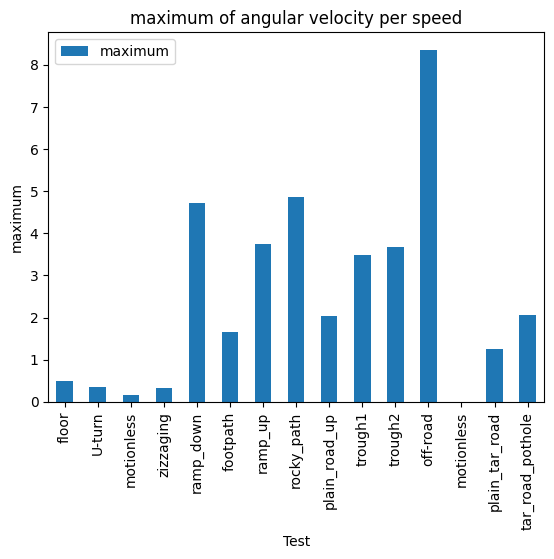

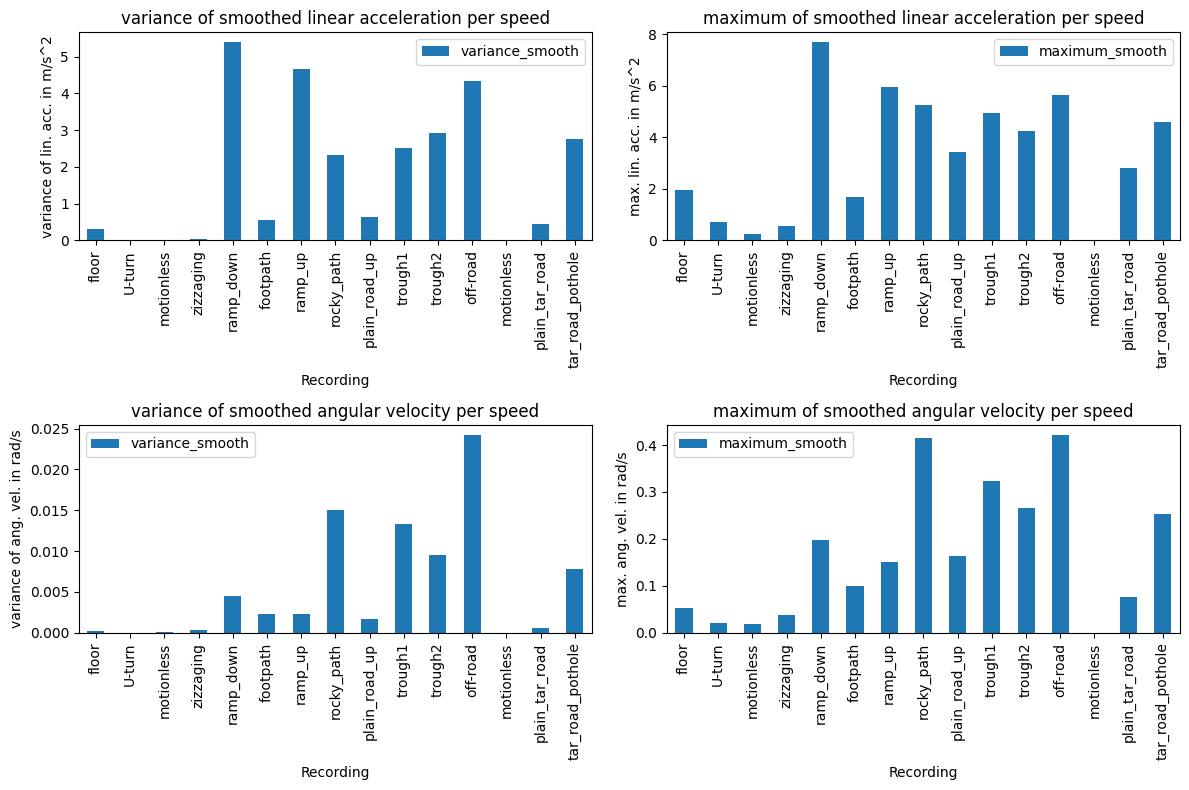

[-0.00705497382198952, -0.03819277108433735, -0.8489655172413794, -0.19622489959839357, -1.2543697478991596, 0.5959113300492611, 1.0055587392550143, -0.39321995464852605, nan, 0.6021564059900166, -0.4355679702048417, 0.5162823529411765, nan, nan, -0.4197196261682243, nan, nan, -0.08998468606431853, 0.1801660516605166, nan]
[-0.09767015706806281, -0.33638554216867467, -1.1836206896551722, 0.33449799196787144, -0.045154061624649876, 0.013743842364532051, -0.15290830945558737, -0.22993197278911562, nan, -0.12139767054908485, -0.3985288640595903, -0.2672941176470588, nan, nan, -0.00976635514018692, nan, nan, -0.14143950995405818, 0.5269372693726938, nan]
[9.84764397905759, 9.892213855421687, 9.623275862068965, 9.870120481927712, 9.869411764705882, 9.579261083743843, 9.875315186246418, 9.896938775510202, nan, 10.042009983361064, 9.775679702048418, 9.848917647058826, nan, nan, 10.211191588785047, nan, nan, 9.639938744257273, 9.40332103321033, nan]
[-0.0033056170518793128, 0.00467085855541253

In [2]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statistics

desktop_path = r"C:\Users\stratklar\Documents\Markus\ASA\Indien\ASA_LIMO_data"
variances = []
var_az_scaled = []
var_gx_scaled = []
max_az_scaled = []
max_gx_scaled = []
var_az_smooth = []
max_az_smooth = []
var_gx_smooth = []
max_gx_smooth = []

ax_mean = []
ay_mean = []
az_mean = []
gx_mean = []
gy_mean = []
gz_mean = []

ax_mean_weighted = 0
ay_mean_weighted = 0
az_mean_weighted = 0
gx_mean_weighted = 0
gy_mean_weighted = 0
gz_mean_weighted = 0

time_total = 0

tests = ["floor", "U-turn", "motionless", "zizzaging", "ramp_down", "footpath", "ramp_up", "rocky_path", "handheld", "plain_road_up", "trough1", "trough2", "handheld", "handheld", "off-road", "handheld", "motionless", "plain_tar_road", "tar_road_pothole", "handheld"]

#variances
#scaling using vx
#cumulative gx to obtain qx, maybe also qy
#lidar
#camera

for i in range(20):
    
    path = os.path.join(desktop_path,f"my_all_sensor_data_test{i+1}")
    lidar_dir = os.path.join(path,"extracted_lidar", "lidar_data_v2.csv")
    imu_dir = os.path.join(path,"extracted_imu", "imu_data_v3.csv")
    odom_dir = os.path.join(path,"extracted_odom", "odom_data_v3.csv")

    lidar = pd.read_csv(lidar_dir)
    imu = pd.read_csv(imu_dir)
    odom = pd.read_csv(odom_dir)
    imu["imu_Timestamp"] = imu["Timestamp"]

    df = pd.merge_asof(
    odom.sort_values("Timestamp"),
    imu.sort_values("Timestamp"),
    on="Timestamp",
    direction="nearest",
    tolerance=20000000
    )[["vx", "imu_Timestamp", "Timestamp", "ax", "ay", "az", "gx", "gy", "gz"]]

    df["az/vx"] = df["az"] / (df["vx"].abs() + 0.001)
    df["gx/vx"] = df["gx"] / (df["vx"].abs() + 0.001)

    #df["az_smooth"] = df["az"].rolling(window=11, center=True, min_periods=1).mean()
    df["az_smooth"] = df["az"].rolling(window=51, center=True).mean()
    df["gx_smooth"] = df["gx"].rolling(window=51, center=True).mean()
    df["vx_smooth"] = df["vx"].rolling(window=51, center=True).mean()
    
    #df["az_smooth/vx"] = (df["az_smooth"] - df["az_smooth"].mean()) / (df["vx_smooth"].abs() + 0.001)
    #df["gx_smooth/vx"] = (df["gx_smooth"] - df["gx_smooth"].mean()) / (df["vx_smooth"].abs() + 0.001)
    df = df[df["vx"] > 0.1]
    df["az_smooth/vx"] = (df["az_smooth"] - df["az_smooth"].mean()) / (df["vx_smooth"].abs())
    df["gx_smooth/vx"] = (df["gx_smooth"] - df["gx_smooth"].mean()) / (df["vx_smooth"].abs())
    
    variances.append(float(imu["az"].var()))
    var_az_scaled.append(float(df["az/vx"].var()))
    #var_gx_scaled.append(float(df["gx/vx"].var()))
    max_az_scaled.append(float(df["az/vx"].abs().max()))
    max_gx_scaled.append(float(df["gx/vx"].abs().max()))

    var_az_smooth.append(float(df["az_smooth/vx"].var()))
    max_az_smooth.append(float(df["az_smooth/vx"].abs().max()))

    var_gx_smooth.append(float(df["gx_smooth/vx"].var()))
    max_gx_smooth.append(float(df["gx_smooth/vx"].abs().max()))

    ax_mean.append(float(df["ax"].mean()))
    ay_mean.append(float(df["ay"].mean()))
    az_mean.append(float(df["az"].mean()))
    gx_mean.append(float(df["gx"].mean()))
    gy_mean.append(float(df["gy"].mean()))
    gz_mean.append(float(df["gz"].mean()))

    #df["imu_Timestamp"] = pd.to_numeric(df["imu_Timestamp"].dropna(), errors="coerce")
    if tests[i] != "handheld" and tests[i] != "motionless":
        time_range = float((df["imu_Timestamp"].max() - df["imu_Timestamp"].min()) / 1000000000)
        #time_range = float(df["imu_Timestamp"].range() / 1000000000)
        time_total += time_range

        ax_mean_weighted += df["ax"].mean() * time_range
        ay_mean_weighted += df["ay"].mean() * time_range
        az_mean_weighted += df["az"].mean() * time_range
        gx_mean_weighted += df["gx"].mean() * time_range
        gy_mean_weighted += df["gy"].mean() * time_range
        gz_mean_weighted += df["gz"].mean() * time_range

variances
var_az_scaled
var_gx_scaled

"""
gx_variances = pd.DataFrame({
    "Test": tests,
    "variance": var_gx_scaled
})
gx_variances = gx_variances[gx_variances["Test"] != "handheld"]

gx_variances.plot(x = "Test", y = "variance", kind = "bar")
plt.xlabel("Test")
plt.ylabel("variance")
plt.title("variance of angular velocity per speed")
plt.show()

az_variances = pd.DataFrame({
    "Test": tests,
    "variance": max_az_scaled
})
az_variances = az_variances[az_variances["Test"] != "handheld"]

az_variances.plot(x = "Test", y = "variance", kind = "bar")
plt.xlabel("Test")
plt.ylabel("variance")
plt.title("variance of linear acceleration per speed")
plt.show()
"""

gx_max = pd.DataFrame({
    "Test": tests,
    "maximum": max_gx_scaled
})
gx_max = gx_max[gx_max["Test"] != "handheld"]

gx_max.plot(x = "Test", y = "maximum", kind = "bar")
plt.xlabel("Test")
plt.ylabel("maximum")
plt.title("maximum of angular velocity per speed")
plt.show()

"""
az_max = pd.DataFrame({
    "Test": tests,
    "maximum": max_az_scaled
})
az_max = az_max[az_max["Test"] != "handheld"]

az_max.plot(x = "Test", y = "maximum", kind = "bar")
plt.xlabel("Test")
plt.ylabel("maximum")
plt.title("maximum of linear acceleration per speed")
plt.show()
"""
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

az_var_smooth = pd.DataFrame({
    "Test": tests,
    "variance_smooth": var_az_smooth
})
az_var_smooth = az_var_smooth[az_var_smooth["Test"] != "handheld"]

az_var_smooth.plot(x = "Test", y = "variance_smooth", kind = "bar", ax = axes[0,0])
axes[0, 0].set_xlabel("Recording")
axes[0, 0].set_ylabel("variance of lin. acc. in m/s^2")
axes[0, 0].set_title("variance of smoothed linear acceleration per speed")

az_max_smooth = pd.DataFrame({
    "Test": tests,
    "maximum_smooth": max_az_smooth
})
az_max_smooth = az_max_smooth[az_max_smooth["Test"] != "handheld"]

az_max_smooth.plot(x = "Test", y = "maximum_smooth", kind = "bar", ax = axes[0,1])
axes[0, 1].set_xlabel("Recording")
axes[0, 1].set_ylabel("max. lin. acc. in m/s^2")
axes[0, 1].set_title("maximum of smoothed linear acceleration per speed")
#plt.xlabel("Test")
#plt.ylabel("max. lin. acc. in m/s^2")
#plt.title("maximum of smoothed linear acceleration per speed")
#plt.show()

#gx_var_smooth
gx_var_smooth = pd.DataFrame({
    "Test": tests,
    "variance_smooth": var_gx_smooth
})
gx_var_smooth = gx_var_smooth[gx_var_smooth["Test"] != "handheld"]

gx_var_smooth.plot(x = "Test", y = "variance_smooth", kind = "bar", ax = axes[1,0])
axes[1, 0].set_xlabel("Recording")
axes[1, 0].set_ylabel("variance of ang. vel. in rad/s")
axes[1, 0].set_title("variance of smoothed angular velocity per speed")

#gx_max_smooth
gx_max_smooth = pd.DataFrame({
    "Test": tests,
    "maximum_smooth": max_gx_smooth
})
gx_max_smooth = gx_max_smooth[gx_max_smooth["Test"] != "handheld"]

gx_max_smooth.plot(x = "Test", y = "maximum_smooth", kind = "bar", ax = axes[1, 1])
axes[1, 1].set_xlabel("Recording")
axes[1, 1].set_ylabel("max. ang. vel. in rad/s")
axes[1, 1].set_title("maximum of smoothed angular velocity per speed")

plt.tight_layout()

# Export as one image
plt.savefig("four_plots.png", dpi=300, bbox_inches="tight")

plt.show()
"""
qx = pd.DataFrame({
    "Test": tests,
    "maximum_smooth": qx_from_gx
})
az_max_smooth = az_max_smooth[az_max_smooth["Test"] != "handheld"]

az_max_smooth.plot(x = "Test", y = "maximum_smooth", kind = "bar")
plt.xlabel("Test")
plt.ylabel("maximum")
plt.title("maximum of smoothed linear acceleration per speed")
plt.show()
"""
print(ax_mean)
print(ay_mean)
print(az_mean)
print(gx_mean)
print(gy_mean)
print(gz_mean)

ax_mean_weighted = ax_mean_weighted / time_total
ay_mean_weighted = ay_mean_weighted / time_total
az_mean_weighted = az_mean_weighted / time_total
gx_mean_weighted = gx_mean_weighted / time_total
gy_mean_weighted = gy_mean_weighted / time_total
gz_mean_weighted = gz_mean_weighted / time_total

print(ax_mean_weighted)
print(ay_mean_weighted)
print(az_mean_weighted)
print(gx_mean_weighted)
print(gy_mean_weighted)
print(gz_mean_weighted)

print(time_total)
